1. Handle missing / NaN values
   - Find all missing values in the dataset.
   - Fill NaN values using a proper strategy (mean, median, mode, or a suitable placeholder depending on the column). Explain why you chose that method.

2. Handle duplicate values
   - Detect duplicate rows in the dataset.
   - Remove all duplicates.

3. Detect outliers
   - Identify outliers in the numeric columns (for example: price, minimum_nights, availability_365).
   - Show them using a method of your choice (IQR, boxplot, etc.) and handle them appropriately.

4. Fix data types
   - Some columns have the wrong data type (for example, price is stored as text). Convert them to the correct type.

5. Convert discrete values into continuous
   - Where required, convert discrete values into continuous values.

6. Visualization (plots)
   - Create proper plots/graphs for your cleaned data (missing values heatmap, price distribution, room type counts, neighbourhood group analysis, etc.).

7. Final verification (very important)
   - At the END of your file, use df.info() and df.isnull().sum() to show that the data is now fully cleaned and has no missing values left.

## 
1. Handle missing / NaN values
   - Find all missing values in the dataset.
   - Fill NaN values using a proper strategy (mean, median, mode, or a suitable placeholder depending on the column).
       Explain why you chose that method.

In [63]:
import pandas as pd 
data=pd.read_csv("airbnb.csv")
data
data.isnull().sum()

id                                  0
name                              271
host_id                             0
host_name                         127
neighbourhood_group                 0
neighbourhood                       5
latitude                            5
longitude                           0
room_type                           0
price                               0
minimum_nights                      0
number_of_reviews                   0
last_review                        13
reviews_per_month                  54
calculated_host_listings_count      1
availability_365                    0
dtype: int64

In [110]:
lat_median = data['latitude'].median()
data['latitude'] = data['latitude'].fillna(lat_median)
lat_median
data['calculated_host_listings_count'] = pd.to_numeric(data['calculated_host_listings_count'], errors='coerce')
listings_median = data['calculated_host_listings_count'].median()
data['calculated_host_listings_count'] = data['calculated_host_listings_count'].fillna(listings_median)
listings_median = data['calculated_host_listings_count'].median()
data['calculated_host_listings_count'] = data['calculated_host_listings_count'].fillna(listings_median)
listings_median

10.0

In [108]:
data.isnull().sum()

id                                   0
name                                 0
host_id                              0
host_name                            0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                          0
reviews_per_month                    0
calculated_host_listings_count       0
availability_365                     0
neighbourhood_group_BRONX            0
neighbourhood_group_BROOKLYN         0
neighbourhood_group_Bronx            0
neighbourhood_group_Brooklyn         0
neighbourhood_group_Brooklyn         0
neighbourhood_group_MANHATTAN        0
neighbourhood_group_Manhatan         0
neighbourhood_group_Manhattan        0
neighbourhood_group_QUEENS           0
neighbourhood_group_Queens           0
neighbourhood_group_State

In [107]:
data['name'] = data['name'].fillna('Unknown')
data['host_name'] = data['host_name'].fillna('Unknown')
data.isnull().sum()
data['reviews_per_month'] = data['reviews_per_month'].fillna(0)
data['last_review'] = data['last_review'].fillna('No Review')
data['neighbourhood'] = data['neighbourhood'].fillna('Unknown')

In [106]:
data.isnull().sum()

id                                   0
name                                 0
host_id                              0
host_name                            0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                          0
reviews_per_month                    0
calculated_host_listings_count       0
availability_365                     0
neighbourhood_group_BRONX            0
neighbourhood_group_BROOKLYN         0
neighbourhood_group_Bronx            0
neighbourhood_group_Brooklyn         0
neighbourhood_group_Brooklyn         0
neighbourhood_group_MANHATTAN        0
neighbourhood_group_Manhatan         0
neighbourhood_group_Manhattan        0
neighbourhood_group_QUEENS           0
neighbourhood_group_Queens           0
neighbourhood_group_State

In [66]:

data_duplicates= data.duplicated().sum()
data_duplicates
data= data.drop_duplicates()
data

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,10,Spacious 2BR,75847,Maria,brooklyn,Greenpoint,40.59158,-73.73783,Private room,97778,5,36,4/9/2019,4.86,19.0,276
1,286,Cozy apartment near park,84558,Chris,staten island,St. George,40.50063,-74.09041,private room,178,1,377,14/10/2014,0.46,7.0,179
2,675,Cozy apartment near park,20892,Daniel,QUEENS,Elmhurst,40.88867,-74.02696,entire home/apt,72,365,99,11/8/2013,1.99,19.0,181
3,100,Cozy apartment near park,90224,Anna,BRONX,Fordham,40.81046,-73.86895,private room,365,1,298,3/17/2018,7.21,8.0,194
4,668,Unknown,35757,John,QUEENS,Ridgewood,40.87452,-73.71388,entire home/apt,244,1,186,1/3/2012,2.05,20.0,206
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1035,920,Unknown,35854,Robert,BRONX,Mott Haven,40.54088,-74.04306,Entire home/apt,108,5,296,14/11/2014,5.43,18.0,422
1036,212,Quiet private room,32502,John,The Bronx,Fordham,40.63243,-73.98257,Shared room,139,1000,271,9/27/2018,0,20.0,342
1037,503,Beautiful loft,43343,Daniel,QUEENS,Astoria,40.55864,-74.04089,PRIVATE ROOM,24482,30,369,2/4/2018,4.28,5.0,142
1038,538,Quiet private room,43317,David,BROOKLYN,Bedford-Stuyvesant,40.89359,-73.90267,private room,0,1,191,1/8/2012,8.26,14.0,71


3. Detect outliers
   - Identify outliers in the numeric columns (for example: price, minimum_nights, availability_365).
   - Show them using a method of your choice (IQR, boxplot, etc.) and handle them appropriately.

In [67]:
data['price'] = data['price'].str.replace('$', '', regex=False)
data['price'] = data['price'].str.strip()
data['price'] = pd.to_numeric(data['price'], errors='coerce')
Q1 = data['price'].quantile(0.25)
Q3 = data['price'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = data[(data['price'] < lower) | (data['price'] > upper)]
outliers


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,10,Spacious 2BR,75847,Maria,brooklyn,Greenpoint,40.59158,-73.73783,Private room,97778.0,5,36,4/9/2019,4.86,19.0,276
14,891,Quiet private room,43844,David,Staten island,Stapleton,40.52795,-74.07782,entire home/apt,79847.0,2,341,9/16/2018,1.13,5.0,251
21,519,Unknown,91819,Olivia,Manhatan,Midtown,40.80127,-74.03419,PRIVATE ROOM,-269.0,5,214,8/18/2018,7.84,19.0,356
51,784,Cozy apartment near park,57807,Chris,brooklyn,Greenpoint,40.74517,-73.96123,Shared room,57876.0,5,145,1/26/2016,5.86,17.0,224
64,866,Unknown,24651,Lisa,Brooklyn,Bedford-Stuyvesant,40.59438,-73.93797,Entire Home/Apt,-490.0,1,7,1/13/2016,1.44,8.0,337
82,223,Modern studio,69337,Anna,brooklyn,Bedford-Stuyvesant,40.76743,-73.89285,Private room,-239.0,5,198,8/2/2018,9.81,9.0,165
90,359,Modern studio,55304,Anna,Bronx,Riverdale,40.67084,-73.96107,Shared room,-460.0,1,333,26/09/2015,4.33,13.0,276
151,464,Cozy apartment near park,14970,Robert,Queens,Ridgewood,40.57594,-73.94474,Entire Home/Apt,13111.0,7,163,11/26/2016,5.2,13.0,308
164,337,Beautiful loft,48325,Sofia,manhattan,Chelsea,40.77083,-73.71695,Private room,75570.0,365,201,8/11/2014,6.05,13.0,28
210,499,Unknown,14938,Olivia,Brooklyn,Bedford-Stuyvesant,40.75779,-74.0825,entire home/apt,6776.0,2,394,5/5/2012,6,18.0,4


In [68]:
data['price'].dtype

dtype('float64')

In [69]:
data ['price'] = data['price'].clip(lower = lower , upper = upper )
after_outliers_data =  data[(data['price'] < lower) | (data['price'] > upper)]
after_outliers_data

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365


In [70]:
data['minimum_nights'].dtype
data['minimum_nights'] = pd.to_numeric(data['minimum_nights'], errors='coerce')
data.isnull().sum()

id                                 0
name                               0
host_id                            0
host_name                          0
neighbourhood_group                0
neighbourhood                      0
latitude                           0
longitude                          0
room_type                          0
price                             18
minimum_nights                     5
number_of_reviews                  0
last_review                        0
reviews_per_month                  0
calculated_host_listings_count     0
availability_365                   0
dtype: int64

In [71]:
minimum_nights_median = data['minimum_nights'].median()
data['minimum_nights'] = data['minimum_nights'].fillna(minimum_nights_median)
minimum_nights_median

5.0

In [72]:
price_median = data['price'].median()
data['price'] = data['price'].fillna(price_median)
price_median


257.0

In [73]:
data.isnull().sum()

id                                0
name                              0
host_id                           0
host_name                         0
neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
last_review                       0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64

In [74]:
Q1 = data['minimum_nights'].quantile(0.25)
Q3 = data['minimum_nights'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers_minimum_nights = data[(data['minimum_nights'] < lower) | (data['minimum_nights'] > upper)]
outliers_minimum_nights

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
2,675,Cozy apartment near park,20892,Daniel,QUEENS,Elmhurst,40.88867,-74.02696,entire home/apt,72.0,365.0,99,11/8/2013,1.99,19.0,181
8,573,Quiet private room,27680,James,QUEENS,Ridgewood,40.60701,-73.82089,Shared room,155.0,365.0,53,6/14/2011,9.51,5.0,248
10,911,Beautiful loft,51070,Maria,The Bronx,Concourse,40.75921,-74.02053,PRIVATE ROOM,282.0,1000.0,224,7/13/2012,5.57,4.0,149
11,473,Quiet private room,69506,Sofia,BRONX,Riverdale,40.62024,-73.72151,private room,366.0,365.0,400,18/11/2015,1.41,12.0,251
25,474,Beautiful loft,35167,Michael,Brooklyn,Williamsburg,40.58609,-74.04632,Entire home/apt,183.0,365.0,110,5/5/2016,6.23,13.0,38
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1018,291,Modern studio,16182,Unknown,Staten island,Stapleton,40.53930,-73.70709,Shared room,103.0,365.0,346,4/24/2013,4.6,1.0,365
1021,764,Beautiful loft,91236,Emma,BROOKLYN,Bushwick,40.86684,-73.9786,entire home/apt,362.0,365.0,309,28/05/2016,5.12,19.0,197
1024,184,Unknown,56549,Emma,Manhatan,East Village,40.86461,-73.84105,private room,257.0,1000.0,4,20/05/2014,7.13,13.0,363
1030,731,Beautiful loft,13528,Anna,QUEENS,Long Island City,40.88845,-74.00843,Private room,430.0,1000.0,312,4/16/2014,4.7,13.0,9


In [75]:
Q1 = data['availability_365'].quantile(0.25)
Q3 = data['availability_365'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers_availability = data[(data['availability_365'] < lower) | (data['availability_365'] > upper)]
outliers_availability

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365


4. Fix data types
   - Some columns have the wrong data type (for example, price is stored as text).
Convert them to the correct type.

In [76]:
data.dtypes

id                                  int64
name                               object
host_id                            object
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                          object
room_type                          object
price                             float64
minimum_nights                    float64
number_of_reviews                  object
last_review                        object
reviews_per_month                  object
calculated_host_listings_count    float64
availability_365                    int64
dtype: object

In [113]:
data['price'] = data['price'].replace('[\$,]', '', regex=True)
data['price'] = pd.to_numeric(data['price'])

In [111]:
data['longitude'] = pd.to_numeric(data['longitude'], errors='coerce')
data['number_of_reviews'] = pd.to_numeric(data['number_of_reviews'], errors='coerce')
data['reviews_per_month'] = pd.to_numeric(data['reviews_per_month'], errors='coerce')
data['last_review'] = pd.to_datetime(data['last_review'], errors='coerce')

In [112]:
data.dtypes

id                                            int64
name                                         object
host_id                                      object
host_name                                    object
neighbourhood                                object
latitude                                    float64
longitude                                   float64
room_type                                    object
price                                       float64
minimum_nights                              float64
number_of_reviews                           float64
last_review                          datetime64[ns]
reviews_per_month                           float64
calculated_host_listings_count              float64
availability_365                              int64
neighbourhood_group_BRONX                      bool
neighbourhood_group_BROOKLYN                   bool
neighbourhood_group_Bronx                      bool
neighbourhood_group_Brooklyn                   bool
neighbourhoo

In [79]:
data[data['reviews_per_month'].isnull()][['number_of_reviews', 'reviews_per_month']]

,number_of_reviews,last_review,reviews_per_month
266,220.0,2018-09-18,NaN


In [80]:
median_rpm = data['reviews_per_month'].median()
data['reviews_per_month'] = data['reviews_per_month'].fillna(median_rpm)
median_rpm

4.425000000000001

In [81]:
data['longitude'] = data['longitude'].fillna(data['longitude'].median())
data['number_of_reviews'] = data['number_of_reviews'].fillna(data['number_of_reviews'].median())
data.isnull().sum()

id                                  0
name                                0
host_id                             0
host_name                           0
neighbourhood_group                 0
neighbourhood                       0
latitude                            0
longitude                           0
room_type                           0
price                               0
minimum_nights                      0
number_of_reviews                   0
last_review                       190
reviews_per_month                   0
calculated_host_listings_count      0
availability_365                    0
dtype: int64

In [82]:
data.columns
data.isnull().sum()

id                                  0
name                                0
host_id                             0
host_name                           0
neighbourhood_group                 0
neighbourhood                       0
latitude                            0
longitude                           0
room_type                           0
price                               0
minimum_nights                      0
number_of_reviews                   0
last_review                       190
reviews_per_month                   0
calculated_host_listings_count      0
availability_365                    0
dtype: int64

5. Convert discrete values into continuous
   - Where required, convert discrete values into continuous values.
   

In [83]:
data = pd.get_dummies(data, columns=['neighbourhood_group'], drop_first=True)
data.head()

,id,name,host_id,host_name,neighbourhood,latitude,longitude,room_type,price,minimum_nights,...,neighbourhood_group_QUEENS,neighbourhood_group_Queens,neighbourhood_group_Staten Island,neighbourhood_group_Staten island,neighbourhood_group_The Bronx,neighbourhood_group_bronx,neighbourhood_group_brooklyn,neighbourhood_group_manhattan,neighbourhood_group_queens,neighbourhood_group_staten island
0,10,Spacious 2BR,75847,Maria,Greenpoint,40.59158,-73.73783,Private room,744.0,5.0,...,False,False,False,False,False,False,True,False,False,False
1,286,Cozy apartment near park,84558,Chris,St. George,40.50063,-74.09041,private room,178.0,1.0,...,False,False,False,False,False,False,False,False,False,True
2,675,Cozy apartment near park,20892,Daniel,Elmhurst,40.88867,-74.02696,entire home/apt,72.0,365.0,...,True,False,False,False,False,False,False,False,False,False
3,100,Cozy apartment near park,90224,Anna,Fordham,40.81046,-73.86895,private room,365.0,1.0,...,False,False,False,False,False,False,False,False,False,False
4,668,Unknown,35757,John,Ridgewood,40.87452,-73.71388,entire home/apt,244.0,1.0,...,True,False,False,False,False,False,False,False,False,False


In [104]:
len(data.columns)

33

In [105]:
data.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood', 'latitude',
       'longitude', 'room_type', 'price', 'minimum_nights',
       'number_of_reviews', 'last_review', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365',
       'neighbourhood_group_BRONX', 'neighbourhood_group_BROOKLYN',
       'neighbourhood_group_Bronx', 'neighbourhood_group_Brooklyn',
       'neighbourhood_group_Brooklyn ', 'neighbourhood_group_MANHATTAN',
       'neighbourhood_group_Manhatan', 'neighbourhood_group_Manhattan',
       'neighbourhood_group_QUEENS', 'neighbourhood_group_Queens',
       'neighbourhood_group_Staten Island',
       'neighbourhood_group_Staten island', 'neighbourhood_group_The Bronx',
       'neighbourhood_group_bronx', 'neighbourhood_group_brooklyn',
       'neighbourhood_group_manhattan', 'neighbourhood_group_queens',
       'neighbourhood_group_staten island'],
      dtype='object')

6. Visualization (plots)
   - Create proper plots/graphs for your cleaned data 
       (missing values heatmap, price distribution, room type counts, neighbourhood group analysis, etc.).


In [97]:
data['room_type'] = data['room_type'].str.lower()
data['room_type'].unique()
data['room_type'] = data['room_type'].replace('???', pd.NA)
data['room_type'].isnull().sum()
data['room_type'] = data['room_type'].fillna(data['room_type'].mode()[0])
data['room_type'].isnull().sum()

np.int64(0)

In [95]:
import matplotlib.pyplot as plt
import seaborn as sns

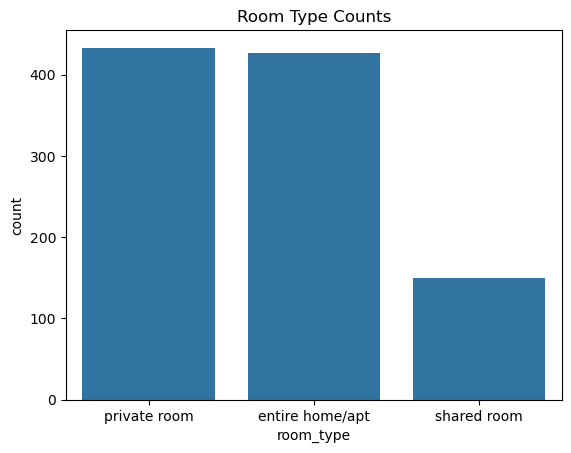

In [98]:
sns.countplot(x='room_type', data=data)
plt.title('Room Type Counts')
plt.show()

Lower Limit: 0
Upper Limit: 734.5


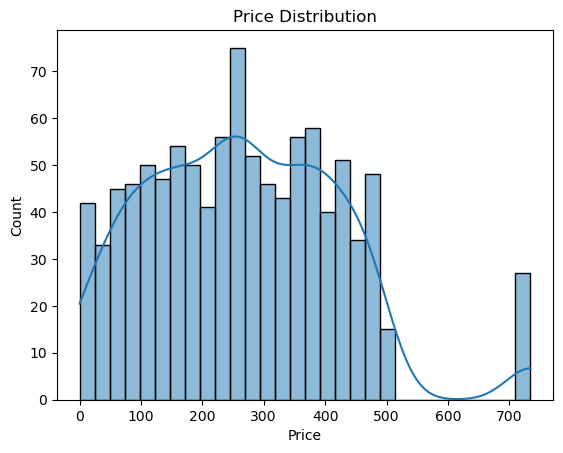

In [99]:
Q1 = data['price'].quantile(0.25)
Q3 = data['price'].quantile(0.75)

IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
lower = max(lower, 0)
data['price'] = data['price'].clip(lower, upper)
print("Lower Limit:", lower)
print("Upper Limit:", upper)
sns.histplot(
    data['price'],
    bins=30, 
    kde=True,
)

plt.title("Price Distribution")
plt.xlabel("Price")
plt.ylabel("Count")

plt.show()

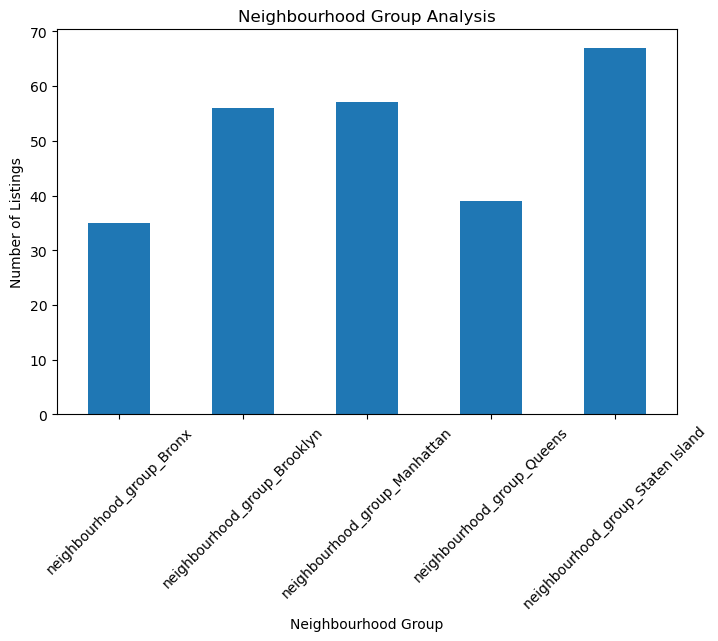

In [87]:
import matplotlib.pyplot as plt

neighbourhood_cols = [
    'neighbourhood_group_Bronx',
    'neighbourhood_group_Brooklyn',
    'neighbourhood_group_Manhattan',
    'neighbourhood_group_Queens',
    'neighbourhood_group_Staten Island'
]

counts = data[neighbourhood_cols].sum()

plt.figure(figsize=(8,5))
counts.plot(kind='bar')
plt.title("Neighbourhood Group Analysis")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45)
plt.show()

7. Final verification (very important)
   - At the END of your file, use df.info() and df.isnull().sum() 
to show that the data is now fully cleaned and has no missing values left.

In [88]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1009 entries, 0 to 1039
Data columns (total 33 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   id                                 1009 non-null   int64         
 1   name                               1009 non-null   object        
 2   host_id                            1009 non-null   object        
 3   host_name                          1009 non-null   object        
 4   neighbourhood                      1009 non-null   object        
 5   latitude                           1009 non-null   float64       
 6   longitude                          1009 non-null   float64       
 7   room_type                          1009 non-null   object        
 8   price                              1009 non-null   float64       
 9   minimum_nights                     1009 non-null   float64       
 10  number_of_reviews                  1009 n

In [89]:
data.isnull().sum()

id                                     0
name                                   0
host_id                                0
host_name                              0
neighbourhood                          0
latitude                               0
longitude                              0
room_type                              0
price                                  0
minimum_nights                         0
number_of_reviews                      0
last_review                          190
reviews_per_month                      0
calculated_host_listings_count         0
availability_365                       0
neighbourhood_group_BRONX              0
neighbourhood_group_BROOKLYN           0
neighbourhood_group_Bronx              0
neighbourhood_group_Brooklyn           0
neighbourhood_group_Brooklyn           0
neighbourhood_group_MANHATTAN          0
neighbourhood_group_Manhatan           0
neighbourhood_group_Manhattan          0
neighbourhood_group_QUEENS             0
neighbourhood_gr

In [90]:
data["last_review"] = data["last_review"].fillna(data["last_review"].mode()[0])

In [91]:
data.isnull().sum()

id                                   0
name                                 0
host_id                              0
host_name                            0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
price                                0
minimum_nights                       0
number_of_reviews                    0
last_review                          0
reviews_per_month                    0
calculated_host_listings_count       0
availability_365                     0
neighbourhood_group_BRONX            0
neighbourhood_group_BROOKLYN         0
neighbourhood_group_Bronx            0
neighbourhood_group_Brooklyn         0
neighbourhood_group_Brooklyn         0
neighbourhood_group_MANHATTAN        0
neighbourhood_group_Manhatan         0
neighbourhood_group_Manhattan        0
neighbourhood_group_QUEENS           0
neighbourhood_group_Queens           0
neighbourhood_group_State

In [92]:
data.head()

,id,name,host_id,host_name,neighbourhood,latitude,longitude,room_type,price,minimum_nights,...,neighbourhood_group_QUEENS,neighbourhood_group_Queens,neighbourhood_group_Staten Island,neighbourhood_group_Staten island,neighbourhood_group_The Bronx,neighbourhood_group_bronx,neighbourhood_group_brooklyn,neighbourhood_group_manhattan,neighbourhood_group_queens,neighbourhood_group_staten island
0,10,Spacious 2BR,75847,Maria,Greenpoint,40.59158,-73.73783,private room,734.5,5.0,...,False,False,False,False,False,False,True,False,False,False
1,286,Cozy apartment near park,84558,Chris,St. George,40.50063,-74.09041,private room,178.0,1.0,...,False,False,False,False,False,False,False,False,False,True
2,675,Cozy apartment near park,20892,Daniel,Elmhurst,40.88867,-74.02696,entire home/apt,72.0,365.0,...,True,False,False,False,False,False,False,False,False,False
3,100,Cozy apartment near park,90224,Anna,Fordham,40.81046,-73.86895,private room,365.0,1.0,...,False,False,False,False,False,False,False,False,False,False
4,668,Unknown,35757,John,Ridgewood,40.87452,-73.71388,entire home/apt,244.0,1.0,...,True,False,False,False,False,False,False,False,False,False


In [93]:
data.tail()

,id,name,host_id,host_name,neighbourhood,latitude,longitude,room_type,price,minimum_nights,...,neighbourhood_group_QUEENS,neighbourhood_group_Queens,neighbourhood_group_Staten Island,neighbourhood_group_Staten island,neighbourhood_group_The Bronx,neighbourhood_group_bronx,neighbourhood_group_brooklyn,neighbourhood_group_manhattan,neighbourhood_group_queens,neighbourhood_group_staten island
1035,920,Unknown,35854,Robert,Mott Haven,40.54088,-74.04306,entire home/apt,108.0,5.0,...,False,False,False,False,False,False,False,False,False,False
1036,212,Quiet private room,32502,John,Fordham,40.63243,-73.98257,shared room,139.0,1000.0,...,False,False,False,False,True,False,False,False,False,False
1037,503,Beautiful loft,43343,Daniel,Astoria,40.55864,-74.04089,private room,734.5,30.0,...,True,False,False,False,False,False,False,False,False,False
1038,538,Quiet private room,43317,David,Bedford-Stuyvesant,40.89359,-73.90267,private room,0.0,1.0,...,False,False,False,False,False,False,False,False,False,False
1039,176,Spacious 2BR,69495,Anna,Elmhurst,40.56045,-73.82141,shared room,167.0,1.0,...,False,False,False,False,False,False,False,False,False,False
